<b><font size="6">PART 2 - OUTLIERS DETECTION</font></b><br><br>

### <font color='#BFD72F'>Table of Contents </font> <a class="anchor" id='toc'></a> 
- [1. Unidimensional Outliers](#o1)
    - [1.1. Detection](#o11)
    - [1.2. Removal](#o12)
    - [1.3. Visualization without outliers](#o13)

- [2. Multidimensional Outliers](#o2)
    - [2.1. Scatter plots detection](#o21)
    - [2.2. BD SCAN detection](#o22)
    - [2.3. K-MEANS detection](#o23)
    - [2.4. Self-organizing Maps detection](#o24)
    - [2.5. Removal](#o25)







<b style="color: orange;">Imports : Libraries and dataset</font></b><br><br>

In [1]:
# BASIC IMPORTS
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd

# VISUALIZATION
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from ipywidgets import interact
from upsetplot import UpSet
from upsetplot import from_indicators

# MODELLING
from sklearn.preprocessing import RobustScaler, MinMaxScaler, StandardScaler
from sklearn.cluster import DBSCAN, KMeans
from minisom import MiniSom
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
import itertools
from scipy.stats import chi2
from scipy.spatial.distance import cdist
from sklearn.manifold import TSNE

# AUXILIARY FUNCTIONS
import Self_utils.py_functions_preproc as pf
import Self_utils.py_functions_outliers as of


In [2]:
df = pd.read_csv("data/raw/train.csv")

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6534 entries, 0 to 6533
Data columns (total 40 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  spend_next_90d                  3425 non-null   float64
 12  days_since_previous_purchase    5673 non-null

<b><font size="6"> 1. Unidimensional Outliers</font></b><br><br> <a id="o1" ></a>
[Back to TOC](#toc)

<b style="color: orange;">1.1 Detection </font></b><br><br>  <a id='o11'></a> 

In [4]:
NUMERIC_COLS = [
    "Total a Pagar",
    "Total Bruto",
    "Total Liquido",
    "Total Imp_",
    "Total Portes",
    "Total Desc_ Global",
    "Total Desc_ Linha",
    "Custo",
    "prior_total_spend",
    "prior_mean_purchase_value",
    "prior_std_purchase_value",
    "prior_min_purchase_value",
    "prior_max_purchase_value",
    "prior_mean_gap_days",
    "prior_std_gap_days",
    "spend_30d",
    "spend_90d",
    "spend_180d",
    "spend_365d",
]

In [5]:
IQR_FEATURES = [
    "Total a Pagar",
    "Total Bruto",
    "Total Liquido",
    "Total Imp_",
    "Custo",
    "prior_total_spend",
    "prior_std_purchase_value",
    "prior_min_purchase_value",
    "prior_max_purchase_value",
    "prior_mean_gap_days",
    "prior_std_gap_days",
    "spend_30d",
    "spend_90d",
    "spend_180d",
]

QUANTILE_FEATURES = [
    "Total Portes",
    "Total Desc_ Global",
    "prior_mean_purchase_value",
    "spend_365d",
    "Total Desc_ Linha",
]


In [6]:
# IDENTIFY OUTLIERS
of.plot_outlier_detection(df, NUMERIC_COLS, multiplier=10)

> As one already concluded, the presence of many one-dimension outliers in all variables makes one have right skewed distribution on all conitnuous features

<b style="color: orange;">1.2. Removal </font></b><br><br>  <a id='o12'></a> 
[Back to TOC](#toc)

In [ ]:
df, out = of.slice_outliers(df, slice=True, multiplier=10)

print('NEW DF: ', df.shape)
print('OUTLIERS DF: ', out.shape)

NEW DF:  (3267, 40)
OUTLIERS DF:  (3267, 40)


> 1924 (1%) observations were kept apart in a outliers dataframe, as they will be used later on for clustering solution acessement

<b style="color: orange;">1.3. Visualization </font></b><br><br>  <a id='o13'></a>
[Back to TOC](#toc)

In [ ]:
of.plot_outlier_detection(df, NUMERIC_COLS)

> Without outliers, one can still verify the presence of right-skewed features, so the presence of outliers, altough biasing the observations, isn´t the only reason behind the distribution of the features

<b><font size="6"> 2. Multidimensional Outliers</font></b><br><br> <a id="o2" ></a>
[Back to TOC](#toc)

<b style="color: orange;">2.1 Scatter plots </font></b><br><br>  <a id='o21'></a> 

In [8]:
# DROP NA
df_clean = df[NUMERIC_COLS].dropna()

# SCALE DATA
scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df_clean), columns=NUMERIC_COLS, index=df_clean.index)

# Mahalanobis
def mahalanobis_distance(xy, mean, cov_inv):
    diff = xy - mean
    return np.sqrt(np.einsum('ij,jk,ik->i', diff, cov_inv, diff))

# PLOT
def plot_pair_outlier(x_col, y_col, conf_level=0.99):
    data_scaled = df_scaled[[x_col, y_col]]
    data_original = df_clean[[x_col, y_col]]

    mean = data_scaled.mean().values
    cov = np.cov(data_scaled.T)
    cov_inv = np.linalg.inv(cov)
    distances = mahalanobis_distance(data_scaled.values, mean, cov_inv)

    threshold = np.sqrt(chi2.ppf(conf_level, df=2))
    is_outlier = distances > threshold

    colors = ['red' if out else 'blue' for out in is_outlier]

    fig = go.Figure()
    fig.add_trace(go.Scattergl(
        x=data_original[x_col],
        y=data_original[y_col],
        mode='markers',
        marker=dict(color=colors, size=6, opacity=0.7),
        text=[f"Outlier: {o}" for o in is_outlier],
    ))

    fig.update_layout(
        title=f"Mahalanobis Outliers (scaled space): {x_col} vs {y_col}",
        xaxis_title=x_col,
        yaxis_title=y_col,
        height=800,
        width=1200
    )
    fig.show()

In [ ]:
interact(plot_pair_outlier,
         x_col=NUMERIC_COLS,
         y_col=NUMERIC_COLS,
         conf_level=(0.90, 0.999, 0.01))

interactive(children=(Dropdown(description='x_col', options=('Total a Pagar', 'Total Bruto', 'Total Liquido', …

<function __main__.plot_pair_outlier(x_col, y_col, conf_level=0.99)>

> We don´t have ay evidence of bi-dimensional outliers

<b style="color: orange;">2.2. BD SCAN </font></b><br><br>  <a id='o22'></a>
[Back to TOC](#toc)

In [23]:
# FEATURE SELECTION
sel_col = [
    "spend_groceries_per_year",
    "spend_vegetables_per_year",
    "spend_nonalcohol_drinks_per_year",
    "spend_meat_per_year",
    "spend_hygiene_per_year",
    "spend_petfood_per_year",
    "total_spend_per_year",
    "spend_electronics_per_year",
    "spend_fish_per_year",
    "spend_alcohol_drinks_per_year",
    'spend_videogames_per_year',
]

# SCALING
df2 = df[sel_col]
scaler = RobustScaler()
X_scaled = scaler.fit_transform(df2)

In [24]:
results_df, top5 = of.dbscan_grid_search_with_silhouette(X_scaled)
print(top5)

     eps  min_samples  n_clusters  n_noise  silhouette_score
16  4.00            4           2      289          0.728823
12  3.25            4           4      569          0.637523
10  2.50            7           2     1546          0.579838
9   2.50            5           6     1405          0.573321
8   2.50            4          12     1334          0.487850


In [25]:
# FINAL DBSCAN
dbscan = DBSCAN(eps=3.125, min_samples=5)
dbscan.fit(X_scaled)

# CLUSTER LABELS
df2['dbscan_cluster'] = dbscan.labels_
df2['db_scan_outlier'] = df2['dbscan_cluster'] == -1

# SUMMARY
print("Number of outliers detected:", df2['db_scan_outlier'].sum())
print("Outlier ratio:", df2['db_scan_outlier'].mean())

Number of outliers detected: 704
Outlier ratio: 0.021193328918056475


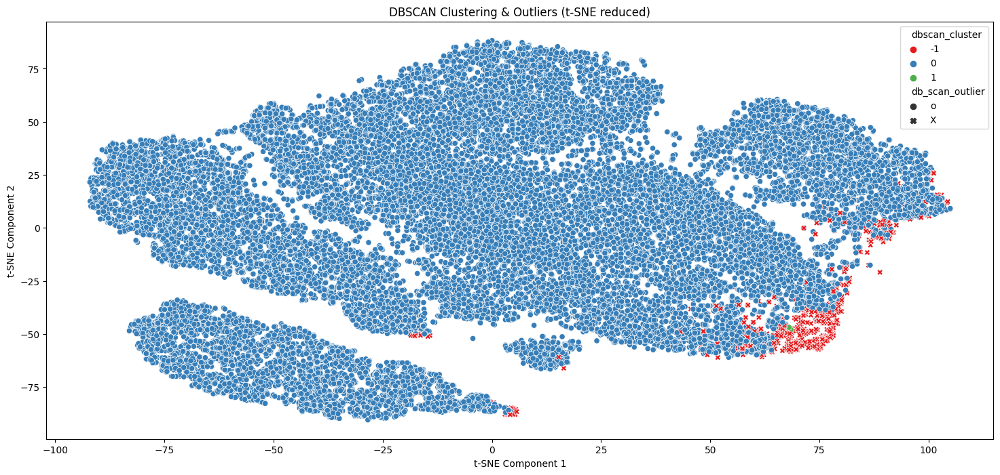

In [26]:
of.plot_tsne_dbscan(X_scaled, df2)

> DB Scan found 698 (2%) of outliers. As an ideal model for outlier detection, these will be likely considered

<b style="color: orange;">2.3. K-MEANS </font></b><br><br>  <a id='o23'></a>
[Back to TOC](#toc)

In [27]:
# FINAL KMEANS
kmeans = KMeans(n_clusters=70, random_state=42)
df2['kmeans_cluster'] = kmeans.fit_predict(X_scaled)

# DISTANCE TO NEAREST CLUSTER CENTER
distances = cdist(X_scaled, kmeans.cluster_centers_)
min_distances = np.min(distances, axis=1)

# OUTLIER TRESHOLD (3%)
threshold = np.percentile(min_distances, 97)
df2['kmeans_outlier'] = min_distances > threshold

# SUMMARY
print("Number of outliers detected:", df2['kmeans_outlier'].sum())
print("Outlier ratio:", df2['kmeans_outlier'].mean())

Number of outliers detected: 997
Outlier ratio: 0.030013847913781685


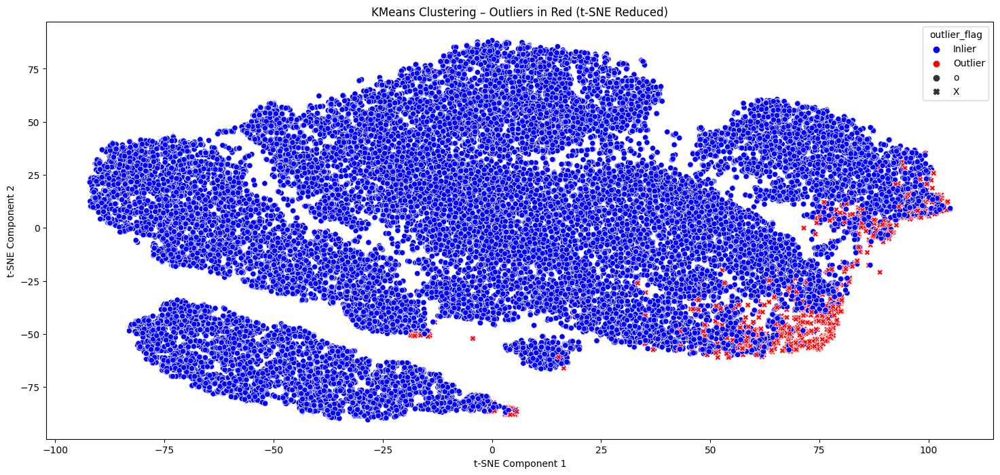

In [28]:
of.plot_tsne_kmeans_outliers(X_scaled, df2)

In [29]:
of.plot_kmeans_cluster_bar(df2)

> K-Means is not ideal for outlier detection, so a residual amount was considered in order to compare it with other clustering solutions. 997 (3%) were considered as outliers

<b style="color: orange;">2.4. Self-Organizing Maps </font></b><br><br>  <a id='o24'></a>
[Back to TOC](#toc)

In [30]:
# TRAIN SOM
som_size = 10 
som = MiniSom(x=som_size, y=som_size, input_len=X_scaled.shape[1], sigma=1.0, learning_rate=0.5, random_seed=42)
som.random_weights_init(X_scaled)
som.train(X_scaled, num_iteration=1000)

# ASSIGN BMU
bmu_coords = np.array([som.winner(x) for x in X_scaled])
bmu_labels = [f"{x}_{y}" for x, y in bmu_coords]
df2['som_cluster'] = bmu_labels

# COMPUTE DISTANCES TO BMU
weights = som.get_weights()
distances = np.array([
    np.linalg.norm(x - weights[bmu[0], bmu[1]])
    for x, bmu in zip(X_scaled, bmu_coords)
])
df2['som_distance'] = distances

# OUTLIER TRESHOLD: 3%
threshold = np.percentile(distances, 97)
df2['som_outlier'] = df2['som_distance'] > threshold

print("Number of outliers detected:", df2['som_outlier'].sum())
print("Outlier ratio:", df2['som_outlier'].mean())

Number of outliers detected: 997
Outlier ratio: 0.030013847913781685


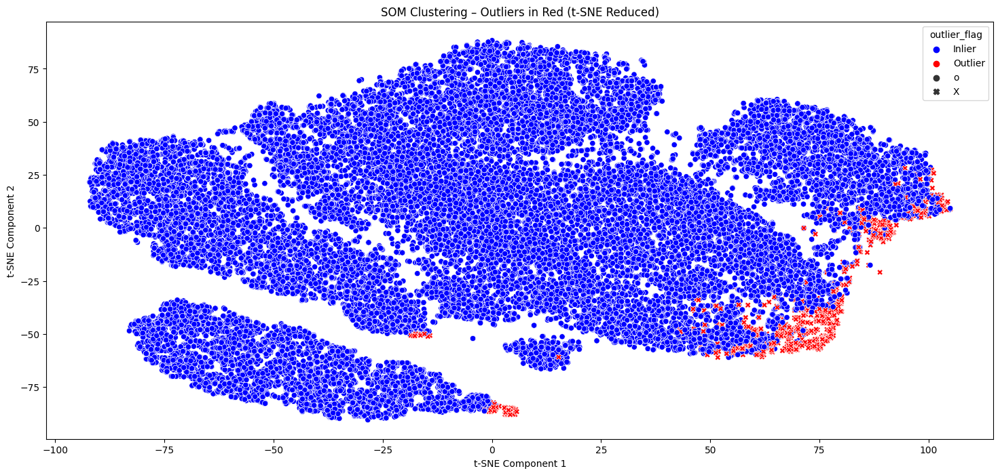

In [31]:
of.plot_tsne_outliers(X_scaled, df2)

> SOM considered 940 observations as outliers. Too many, but as TSNE visualization shows, it also detects well the real outliers.

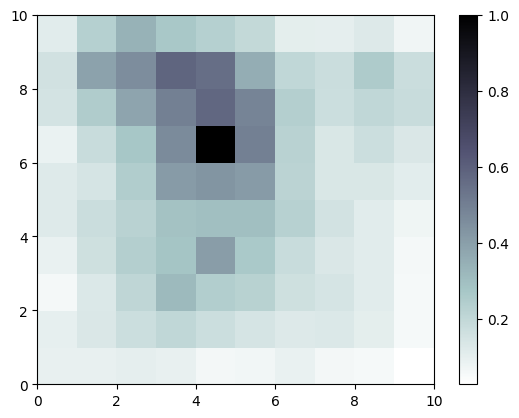

In [32]:
# Distance map of our nodes
plt.pcolor(som.distance_map().T, cmap='bone_r')
plt.colorbar()

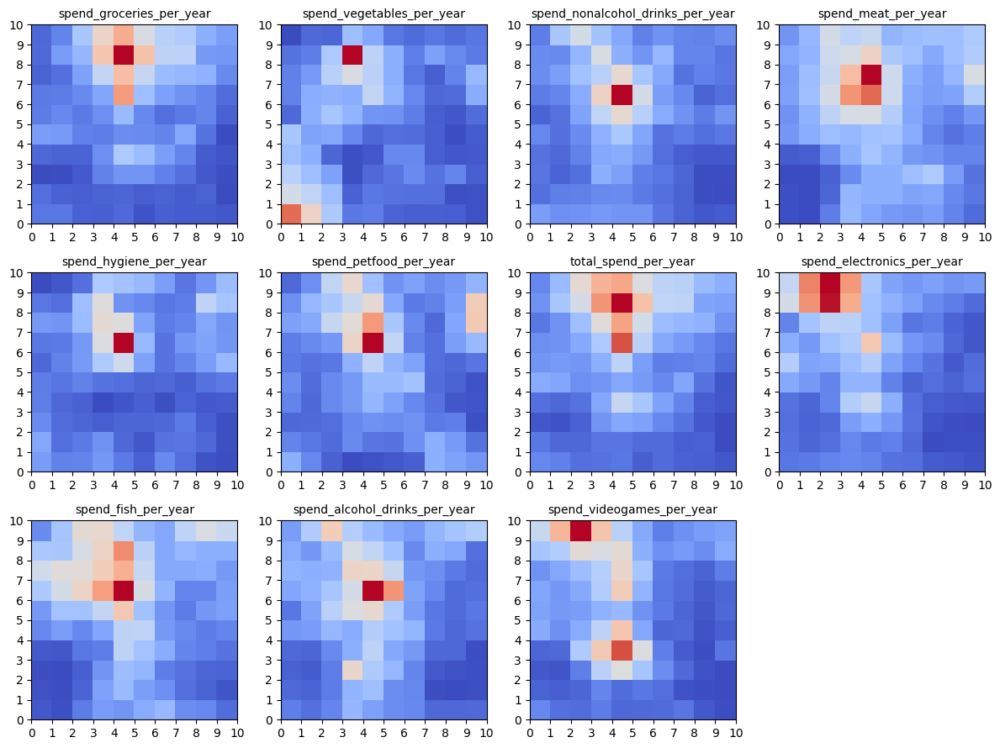

In [33]:
su.plot_feature_influence(som, df2[sel_col])

> SOM also allows to understand the feature importance: all of them all contributing to the detection of outliers

<b style="color: orange;">2.5. Removal </font></b><br><br>  <a id='o25'></a>
[Back to TOC](#toc)

In [34]:
# DROP VARIABLES
df2.drop(columns=['kmeans_cluster', 'dbscan_cluster',
                  'som_cluster', 'som_distance', 'outlier_flag'], inplace=True)

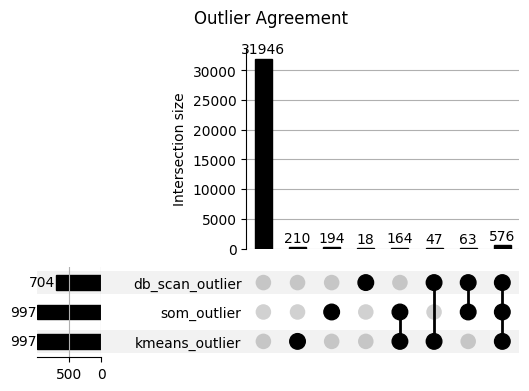

In [35]:
of.plot_outlier_agreement(df2)

> 954 observations were considered as outliers by all algorithms. Those are the ones most certain of being outliers, so they will be the ones considered

In [36]:
unidim_out = 840
multidim_out = 573
outlier_perc = (unidim_out + multidim_out) / 34060
print(outlier_perc)

0.041485613623018204


> 3% of the data were considered as outliers, unidimensional and multidimensional, which will be kept in a dataframe, useful later for solution acessment

In [37]:
# GET MULTIDIMENSIONAL OUTLIERS
multi_outliers = df2[(df2['db_scan_outlier'] == True) &
                     (df2['som_outlier'] == True) &
                     (df2['kmeans_outlier'] == True)]

# GET MULTIDIM OUTLIERS FROM ORIGINAL DATAFRAME
multi_out_from_df = df.loc[multi_outliers.index]

# APPEND MULTIDIMENSIONAL OUTLIERS TO UNIDIM OUTLIERS
out = pd.concat([out, multi_out_from_df]).drop_duplicates()

# REMOVE ALL OUTLIERS FROM ORIGINAL DATAFRAME
df_cleaned = df.drop(multi_outliers.index)

In [38]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 32642 entries, 0 to 34059
Data columns (total 26 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Unnamed: 0                        32642 non-null  int64  
 1   customer_id                       32642 non-null  int64  
 2   distinct_stores_visited           32642 non-null  int64  
 3   lifetime_total_distinct_products  32642 non-null  float64
 4   latitude                          32642 non-null  float64
 5   longitude                         32642 non-null  float64
 6   pct_prod_in_promotion             32642 non-null  float64
 7   degree                            32642 non-null  int64  
 8   male                              32642 non-null  int64  
 9   age                               32642 non-null  int64  
 10  child_home                        32642 non-null  int64  
 11  complained                        32642 non-null  int64  
 12  loyalty_c

In [ ]:
df_cleaned.to_csv('Data/cleaned_df', index=False)
out.to_csv('Data/outlier_df', index=False)